## Load Study Data

In [3]:
##imports
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
import sys

%matplotlib inline
from matplotlib import pyplot as plt
sys.path.append(os.path.join(os.getcwd(), '..'))

from datetime import datetime, timedelta
import importlib
from tqdm import tqdm


from babelbetes.studies.studydataset import StudyDataset
from babelbetes.studies.dataset_initializer import initialize_datasets
from babelbetes import drawing, cdf, tdd, logger, pandas_helper

import logging
logger = logger.Logger.get_logger("",logging.WARNING)

In [ ]:
from babelbetes.studies import Loop
loop_path = os.path.join(os.getcwd(), '..', 'data/raw/Loop study public dataset 2023-01-31')
loop = Loop(loop_path)


In [145]:
df_basal = loop.basal
df_bolus = loop.bolus
df_cgm = loop.cgm


[15:02:32] loop_basal.parquet already exists. Skipping conversion.
[15:03:23] loop_cgm.parquet already exists. Skipping conversion.


In [222]:
#get the raw data
df_patient = pd.read_csv(os.path.join(loop_path, 'Data Tables', 'PtRoster.txt'), sep='|')
df_bolus_raw = pd.read_csv(os.path.join(loop_path, 'Data Tables', 'LOOPDeviceBolus.txt'), sep='|', parse_dates=['UTCDtTm'], date_format='%Y-%m-%d %H:%M:%S')
df_bolus_raw = df_bolus_raw.merge(df_patient[['PtID', 'PtTimezoneOffset']], on='PtID', how='left')
df_bolus_raw['datetime'] = df_bolus_raw.UTCDtTm + pd.to_timedelta(df_bolus_raw.PtTimezoneOffset, unit='hour')
df_bolus_raw[['PtID','PtTimezoneOffset','UTCDtTm','datetime']]


,PtID,PtTimezoneOffset,UTCDtTm,datetime
0,1082,-5.0,2018-04-20 06:01:58,2018-04-20 01:01:58
1,1082,-5.0,2018-04-20 00:43:53,2018-04-19 19:43:53
2,1082,-5.0,2018-04-19 22:56:56,2018-04-19 17:56:56
3,1082,-5.0,2018-04-19 22:36:08,2018-04-19 17:36:08
4,1082,-5.0,2018-04-19 19:58:50,2018-04-19 14:58:50
...,...,...,...,...
2722508,1121,-5.0,2019-12-17 12:14:46,2019-12-17 07:14:46
2722509,1121,-5.0,2019-12-16 03:17:08,2019-12-15 22:17:08
2722510,1121,-5.0,2019-12-14 00:08:18,2019-12-13 19:08:18
2722511,1121,-5.0,2019-12-12 04:12:45,2019-12-11 23:12:45


## Patient 841

In [108]:
patient_id = '841'
df_bolus_p = df_bolus.query("patient_id == @patient_id")
df_basal_p = df_basal.query("patient_id == @patient_id")

In [109]:
#plot tdd
import plotly.express as px

tdd_p = tdd.calculate_tdd(df_bolus_p,df_basal_p)
tdd_p = tdd_p.reset_index()

fig = px.scatter(tdd_p, x='basal', y='bolus', hover_data=['date'])
fig.show()


7,9,28th DEcember 2018 we see three tdd outliers in bolus size. 

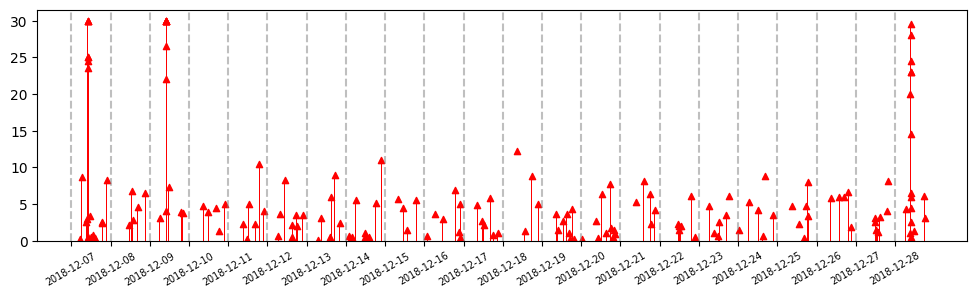

In [ ]:
from datetime import datetime, date
df_bolus_affected = df_bolus_p[df_bolus_p.datetime.dt.date.between(date(2018,12,7),date(2018,12,28))]
f,ax = drawing.default_figure(12,3)
drawing.drawBoluses(ax,df_bolus_affected.datetime,df_bolus_affected.bolus)
drawing.drawMidnightLines(ax,df_bolus_affected.datetime)
plt.xticks(df_bolus_affected.datetime.dt.date.unique(),rotation=30,fontsize='x-small');

In [ ]:

#get dateime (use -6 hour offset as per patient roster)
df_bolus_raw_p = df_bolus_raw[(df_bolus_raw.PtID.astype('str') == '841')]

#affected day bolus sum
affected_dates = [date(2018,12,7),date(2018,12,9),date(2018,12,28)]
display(df_bolus_raw_p[df_bolus_raw_p.datetime.dt.date.isin(affected_dates)].groupby(df_bolus_raw_p.datetime.dt.date).Normal.sum())
display(df_bolus_raw_p[df_bolus_raw_p.datetime.dt.date.isin(affected_dates)].OriginDeviceModel.value_counts())

n_inpen_overall = df_bolus_raw_p.OriginDeviceModel.value_counts().InPen
n_inpen = df_bolus_raw_p[df_bolus_raw_p.datetime.dt.date.isin(affected_dates)].OriginDeviceModel.value_counts().InPen
print(f"The 3 affected days contains {n_inpen/n_inpen_overall:.1%} of InPen Boluses")

datetime
2018-12-07    221.15
2018-12-09    220.75
2018-12-28    198.50
Name: Normal, dtype: float64

OriginDeviceModel
InPen    31
Eros     18
Name: count, dtype: int64

The 3 affected days contains 88.6% of InPen Boluses


Text(0.5, 1.0, '841 bolus doses')

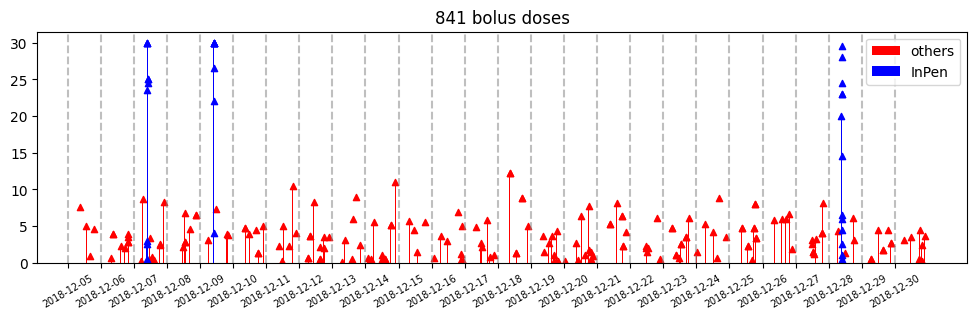

In [100]:
f,ax = drawing.default_figure(12,3)
df_inpen = df_bolus_raw_p[df_bolus_raw_p.datetime.dt.date.between(date(2018,12,5),date(2018,12,30)) & (df_bolus_raw_p.OriginDeviceModel == 'InPen')]
df_others = df_bolus_raw_p[df_bolus_raw_p.datetime.dt.date.between(date(2018,12,5),date(2018,12,30)) & (df_bolus_raw_p.OriginDeviceModel != 'InPen')]
drawing.drawBoluses(ax, df_others.datetime,df_others.Normal,label='others')
drawing.drawBoluses(ax, df_inpen.datetime,df_inpen.Normal,color='blue',label='InPen')
drawing.drawMidnightLines(ax,df_others.datetime)
plt.xticks(df_others.datetime.dt.date.unique(),rotation=30,fontsize='x-small');
plt.legend()
plt.title(f"{patient_id} bolus doses")

In [102]:
display(df_inpen.sort_values('datetime'))

,PtID,RecID,ParentLOOPDeviceUploadsID,DeviceDtTm,UTCDtTm,BolusType,Normal,ExpectedNormal,Extended,ExpectedExtended,...,OriginName,OriginVers,OriginType,OriginDeviceFirmwrVer,OriginDeviceHardwrVer,OriginDeviceManufact,OriginDeviceModel,OriginOperatingSystVer,OriginProductType,datetime
1667553,841,1761870,1094125,NaN,2018-12-07 15:14:14,normal,2.5,NaN,NaN,NaN,...,com.apple.HealthKit,4.0,service,3.48 4Dec17,INPEN GEN1,Companion Medical,InPen,13.1.2,"iPhone10,2",2018-12-07 09:14:14
1667552,841,1761869,1094125,NaN,2018-12-07 15:45:33,normal,3.0,NaN,NaN,NaN,...,com.apple.HealthKit,4.0,service,3.48 4Dec17,INPEN GEN1,Companion Medical,InPen,13.1.2,"iPhone10,2",2018-12-07 09:45:33
1667551,841,1761868,1094125,NaN,2018-12-07 15:53:29,normal,30.0,NaN,NaN,NaN,...,com.apple.HealthKit,4.0,service,3.48 4Dec17,INPEN GEN1,Companion Medical,InPen,13.1.2,"iPhone10,2",2018-12-07 09:53:29
1667550,841,1761867,1094125,NaN,2018-12-07 15:54:43,normal,23.5,NaN,NaN,NaN,...,com.apple.HealthKit,4.0,service,3.48 4Dec17,INPEN GEN1,Companion Medical,InPen,13.1.2,"iPhone10,2",2018-12-07 09:54:43
1667549,841,1761866,1094125,NaN,2018-12-07 15:55:08,normal,30.0,NaN,NaN,NaN,...,com.apple.HealthKit,4.0,service,3.48 4Dec17,INPEN GEN1,Companion Medical,InPen,13.1.2,"iPhone10,2",2018-12-07 09:55:08
1667548,841,1761865,1094125,NaN,2018-12-07 15:55:16,normal,30.0,NaN,NaN,NaN,...,com.apple.HealthKit,4.0,service,3.48 4Dec17,INPEN GEN1,Companion Medical,InPen,13.1.2,"iPhone10,2",2018-12-07 09:55:16
1667547,841,1761864,1094125,NaN,2018-12-07 15:55:53,normal,0.5,NaN,NaN,NaN,...,com.apple.HealthKit,4.0,service,3.48 4Dec17,INPEN GEN1,Companion Medical,InPen,13.1.2,"iPhone10,2",2018-12-07 09:55:53
1667546,841,1761863,1094125,NaN,2018-12-07 16:18:20,normal,24.5,NaN,NaN,NaN,...,com.apple.HealthKit,4.0,service,3.48 4Dec17,INPEN GEN1,Companion Medical,InPen,13.1.2,"iPhone10,2",2018-12-07 10:18:20
1667545,841,1761862,1094125,NaN,2018-12-07 16:20:17,normal,25.0,NaN,NaN,NaN,...,com.apple.HealthKit,4.0,service,3.48 4Dec17,INPEN GEN1,Companion Medical,InPen,13.1.2,"iPhone10,2",2018-12-07 10:20:17
1667544,841,1761861,1094125,NaN,2018-12-07 16:22:44,normal,25.0,NaN,NaN,NaN,...,com.apple.HealthKit,4.0,service,3.48 4Dec17,INPEN GEN1,Companion Medical,InPen,13.1.2,"iPhone10,2",2018-12-07 10:22:44


Probably this user tested the inpen over a couple of days and the priming doses upon cartridge change ended up in the records.

## How many InPen data do we have overall?

In [103]:
counts = df_bolus_raw.groupby('PtID')['OriginDeviceModel'].agg(lambda x: x.eq('InPen').sum())
counts[counts > 0]

PtID
57        2
291     417
407     500
571     363
651      40
683       2
689       6
795     182
841      35
897     208
983     370
1176    247
1195     13
Name: OriginDeviceModel, dtype: int64

## Subject 11

In [230]:
patient_id = '11'
df_bolus_p = df_bolus.query("patient_id == @patient_id")
df_basal_p = df_basal.query("patient_id == @patient_id")
df_cgm_p = df_cgm.query("patient_id == @patient_id")

In [231]:
#tdd
tdd_p = tdd.calculate_tdd(df_bolus_p,df_basal_p)
tdd_p = tdd_p.reset_index()
tdd_p['tdd']=tdd_p.basal+tdd_p.bolus
fig = px.line(tdd_p, x='basal', y='bolus')
fig.add_traces(px.scatter(tdd_p, x='basal', y='bolus', hover_data=['date']).data)
fig.show()

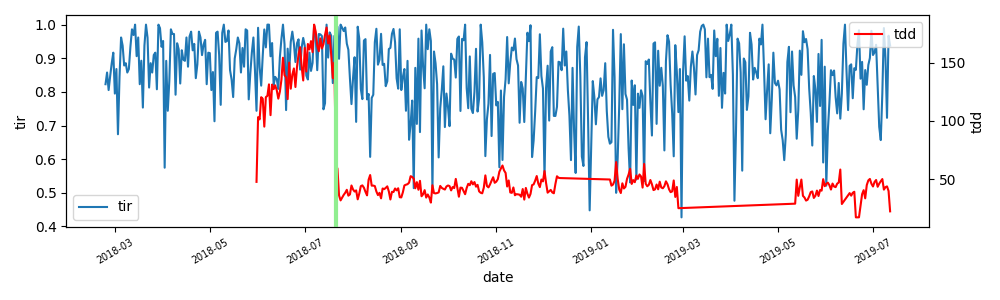

In [302]:
start = date(2018,5,31)
end = date(2018,7,21)
%matplotlib widget
tir_p = df_cgm_p.groupby([df_cgm_p.patient_id, df_cgm_p.datetime.dt.date]).agg(tir = ('cgm', lambda cgm: cgm.between(70,180).mean()))
tir_p = tir_p.reset_index().rename(columns={'datetime':'date'})

import seaborn as sns
f,ax = drawing.default_figure(10,3)
sns.lineplot(tir_p,x='date',y='tir',ax=ax,label='tir')
twinax=ax.twinx()
sns.lineplot(tdd_p,x='date',y='tdd',ax=twinax,color='red',label='tdd')
twinax.axvline(end,color='lightgreen',linewidth=3,zorder=2)
ax.tick_params(axis='x',rotation=30,labelsize='x-small')
plt.tight_layout()
plt.show()


TDD changes but TIR does not! I bet the high TDD comes from a change in therapy.

Again, we see a temporal cluster of days with high total bolus doses. `June 1st 2018` to `20th July 2018`

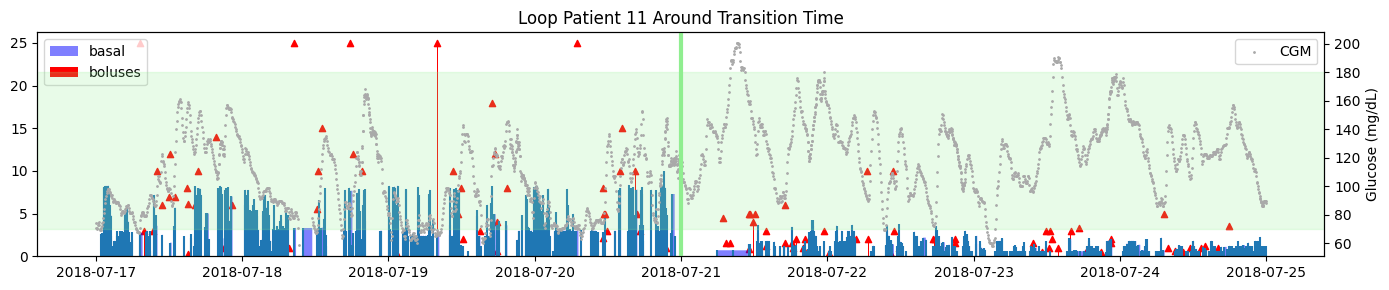

In [291]:
%matplotlib inline
margin = pd.Timedelta('4d')

df_bolus_p_transition = df_bolus_p[df_bolus_p.datetime.dt.date.between(end-margin, end+margin, inclusive="left")]
df_bolus_p_transition['period'] = df_bolus_p_transition.datetime.dt.date.le(end).replace({True:'High',False:'Low'})

df_basal_p_transition = df_basal_p[df_basal_p.datetime.dt.date.between(end-margin,end+margin, inclusive="left")]
df_basal_p_transition['period'] = df_basal_p_transition.datetime.dt.date.le(end).replace({True:'High',False:'Low'})

df_cgm_p_transition = df_cgm_p[df_cgm_p.datetime.dt.date.between(end-margin, end+margin, inclusive="left")]
df_cgm_p_transition['period'] = df_cgm_p_transition.datetime.dt.date.le(end).replace({True:'High',False:'Low'})

f,ax = drawing.default_figure(14,3)
drawing.drawBoluses(ax,df_bolus_p_transition.datetime, df_bolus_p_transition.bolus,width=pd.Timedelta('1min'))
drawing.drawBasal(ax,df_basal_p_transition.datetime, df_basal_p_transition.basal_rate)
ax.legend(loc='upper left')

twinax = ax.twinx()
drawing.drawCGM(twinax,df_cgm_p_transition.datetime, df_cgm_p_transition.cgm,s=1)
twinax.legend(loc='upper right')

twinax.axvline(end,color='lightgreen',linewidth=3,zorder=2)
plt.title("Loop Patient 11 Around Transition Time")
plt.tight_layout()

In [263]:
display(df_bolus_p_transition.groupby('period').bolus.agg(['sum','mean','count']))
display(df_basal_p_transition.groupby('period').basal_rate.agg(['count']))
display(df_cgm_p_transition.groupby('period').cgm.agg([lambda cgm: cgm.between(70,180).mean(),'mean']))

,sum,mean,count
period,,,
High,471.7,6.836232,69
Low,74.8,2.077778,36


,count
period,
High,1144
Low,767


,<lambda_0>,mean
period,,
High,0.927673,110.925536
Low,0.963312,123.387569


Basal and Bolus rates change dramatically.

This is the same patient: CGM trace is continuous and basal rates change with falling glucose. 

**Raw data**

In [268]:
#+- 4 days around end of high tdd
df_bolus_raw_p = df_bolus_raw[(df_bolus_raw.PtID == 11) & (df_bolus_raw.datetime.dt.date.between(end-margin,end+margin,inclusive='left'))]
df_bolus_raw_p = df_bolus_raw_p.drop_duplicates(subset='datetime')
df_bolus_raw_p['period'] = df_bolus_raw_p.datetime.dt.date.le(end).replace({True:'High',False:'Low'})
df_bolus_raw_p.groupby('period').Normal.agg(['sum','mean','count'])

,sum,mean,count
period,,,
High,471.7,6.836232,69
Low,74.8,2.077778,36


Upon inspection of the raw data, we don't see any difference in the meta data of the raw bolus frame

Theories: 
 - User started actual looping 20th of July. Before he used open loop. 
 - User used high boluses for priming. BUt the higher basal rates wouldn't allow explanation
 - User was severely sick? (the increase in TDD could indicate this/pregnancy? Age 38 could indicate this)
 - User switched to higher insulin concentration (U500?) 
 - Medication onset (SGLT2, GLP1,...)
